# Learning Data Dashboard
## Spot a pattern early. Investigate before choosing training.
**Guide Performance Early-Warning System · Priority 1 pilot · manually refreshed.**

This notebook brings together queue operations, sampled call records, selected quality reviews, and voluntary customer feedback. It looks for **sustained changes worth investigating**, rather than automatically deciding that a Guide is underperforming or that a course is needed.

**Read this first:** the saved example uses the fictional case through September 30, 2026, with an October 2 report date. It is a historical demonstration, not proof that Learning detected an issue early. Each manual refresh generates the dashboard, a weekly insight digest, and an investigation backlog. There is no continuously connected live feed or notification service.

### What the four signals mean
| Signal | Question to ask | What the current data supports |
|---|---|---|
| **Handling time** | Are calls taking longer than our starting point? | All-call queue averages and separate sampled product/reason averages |
| **Repeat contacts** | Are households needing to contact us again? | **Not measurable:** no household/account key or complete linked contact history |
| **QA process gaps** | Are reviewed examples showing the same missed behavior? | Selected review signals, not population failure rates |
| **Emerging issues** | Are product or reason patterns changing? | Sample contact mix, call time, and generic-troubleshooting patterns |

**How to use it:** read the cards and charts, open the interactive dashboard, then choose a small number of issues to investigate with Product, Care Quality, Operations and Workforce. Learning owns the investigation process and learning response; other owners may need to fix systems, search, staffing, or policy first.

## 1. Refresh this report — the non-coder’s checklist
1. Archive the previous inputs. Put **full updated exports** of `Orbit_operations.xlsx` and `Quality_and_feedback.xlsx` in `data/raw/`, or a separate folder. Keep the existing sheet names, headers and identifiers; the loader finds the header row automatically. Do not append overlapping exports. Include the baseline, recent full weeks, matching Staffing rows and every sampled Call ID referenced by QA or feedback.
2. Open **`learning_settings.json`**, next to this notebook. Update the input folder and report date. This is the main settings file, used by both the notebook and the weekly command. The visible **EDIT HERE** code cell below lets you override a setting for a one-off run.
3. Choose **Clear All Outputs**, then **Restart Kernel and Run All Cells**. Wait for every cell to finish. If a cell fails, stop: later outputs may be from a previous run. Fix the source/settings and restart/run all again.
4. Check every source date, the comparison periods, and the counts behind each signal. A newer run does not make old data fresh. Save the notebook only after the final **Learning refresh complete** message.
5. Open the output folder printed below. Each run creates its own snapshot containing the HTML dashboard, digest, evidence tables, register and input hashes. `outputs/learning/latest_run.json` points to the most recent successful report. Changing a browser filter does not reload files.

### Settings to change when new data arrives
| Name in `learning_settings.json` | Meaning and example |
|---|---|
| `input_folder` | Folder with both workbooks; `"data/raw"` is relative to this notebook’s folder. Absolute paths also work. |
| `as_of` | Latest permitted event date, e.g. `"2026-10-16"`. All events must be at or before it. |
| `mode` | Keep `"historical_demo"` for this packet and test runs. Use `"pilot"` only for an agreed real pilot; never turn a historical replay into a claimed early detection. |
| `baseline_start`, `baseline_end` | Fixed comparison dates. Keep enough history in both files. A changed baseline changes the question; record why you changed it. |
| `product_grouping` | `"code"` shows individual product codes (default); `"family"` combines WN7/WNM-7, other products, and Unknown. Smaller groups often have too few observations. |
| `window_days` | Recent calendar days in the overview cards; default `7`. |
| `consecutive_weeks` | Consecutive complete Monday–Sunday weeks needed for a flag; default `2`. Partial weeks stay visible but cannot trigger a sustained flag. |
| `min_sample_per_week`, `min_baseline_sample` | Sample sizes required for sampled handling-time comparisons; defaults `20` per week and `40` in the baseline. |
| `min_qa_per_week`, `min_feedback_per_week` | Minimum assessed reviews/responses per weekly rule; default `10`. Counts do not make selected data representative. |
| `aht_increase_fraction`, `volume_increase_fraction` | Proposed trigger: `0.15` means a 15% increase from the baseline. |
| `abandonment_increase_pp`, `segment_share_increase_pp` | Proposed trigger: `5.0` means five percentage points, e.g. 4% to 9%. Product/reason share uses sampled calls, not total demand. |
| `qa_gap_fraction`, `low_feedback_fraction`, `generic_troubleshooting_fraction` | Proposed levels of concern among assessed reviews, responding customers, or eligible sampled calls; `0.35` means 35%. Low feedback means 1 or 2 out of 5. |
| `max_source_age_days` | Age of daily operations beyond which new flags are suppressed; default `3`. Check QA/feedback dates and rule counts separately. |
| `guide_view_approved` | Default `false`. Leave off unless a manager/Quality owner has approved a private coaching use and reviewed reliability and case mix. |
| `min_guide_calls`, `min_guide_reviews`, `min_guide_weeks` | Proposed minimums if approved: `100` calls, `20` distinct reviewed calls, `4` weeks. These are screening rules, not proof of fair comparison. |
| `output_folder`, `issue_log` | Snapshot folder and persistent investigation log. Keep the same log across refreshes; do not replace it with a blank file. |

**All thresholds are starting proposals for review.** Tune them with Quality and Workforce, document changes, and review false alarms/missed issues. A flag is a request for investigation, not a validated statistical alarm.

In [1]:
# EDIT HERE — optional one-run settings overrides.
# For normal weekly use, edit learning_settings.json and leave OVERRIDES empty.
SETTINGS_FILE = 'learning_settings.json'
OVERRIDES = {}
# Example for later exports (remove the leading # to use):
# OVERRIDES = {'input_folder': '/workspace/new_exports', 'as_of': '2026-10-16'}
# Keep mode='historical_demo' for synthetic test data.

In [2]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd()/'learning_monitor.py').exists() else Path.cwd()/'northstar_analysis'
assert (ROOT/'learning_monitor.py').exists(), 'Run from northstar_analysis or its parent.'
sys.path.insert(0,str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown, IFrame, FileLink
from presentation import cards, table
from learning_monitor import read_settings, run
config_path=Path(SETTINGS_FILE)
if not config_path.is_absolute():config_path=ROOT/config_path
settings=read_settings(config_path)
settings.update(OVERRIDES)
for key in ['input_folder','output_folder','issue_log']:
    p=Path(settings[key]).expanduser()
    settings[key]=str(p if p.is_absolute() else ROOT/p)
report=run(settings)
D=report['data']; flags=report['flags']; out=report['out']
display(Markdown(f"**Report date:** {settings['as_of']} · **Mode:** {settings['mode']}  \n**Successful snapshot:** `{out}`  \n**Source folder:** `{settings['input_folder']}`"))
table(report['coverage'].assign(**{'Latest date':report['coverage']['Latest date'].dt.strftime('%Y-%m-%d')}),
 'Check the age of every source', 'Reviews can arrive after their calls. Recent daily totals do not make an old call sample fresh. Missing or stale evidence is not an all-clear.')

**Report date:** 2026-10-02 · **Mode:** historical_demo  
**Successful snapshot:** `/workspace/kirby/northstar_analysis/outputs/learning/20261106T215129069639Z`  
**Source folder:** `/workspace/kirby/northstar_analysis/data/raw`

Source,Queue,Records,Latest date,Age in days,Freshness
daily,General Care,183,2026-09-30,2,Within age setting
daily,Specialist Care,183,2026-09-30,2,Within age setting
staff,General Care,183,2026-09-30,2,Within age setting
staff,Specialist Care,183,2026-09-30,2,Within age setting
calls,General Care,18854,2026-09-30,2,Within age setting
calls,Specialist Care,1146,2026-09-30,2,Within age setting
qa,General Care,1457,2026-10-01,1,Within age setting
qa,Specialist Care,143,2026-10-01,1,Within age setting
feedback,General Care,1998,2026-10-01,1,Within age setting
feedback,Specialist Care,202,2026-10-01,1,Within age setting


## 2. What needs attention this week?
**All-call figures and selected evidence stay separate.** Queue averages weight busier days by answered calls; arriving calls are per day; callers leaving before help are abandoned/arriving calls. These are full daily records.

Product and reason labels come from sampled calls, which are not total demand. QA and feedback are deliberately nonrandom. Percentages always belong to the group actually examined. Missing product/reason codes stay “Unknown”; the loader does not guess them.

In [3]:
for queue,d in D['ops'].groupby('Queue'):
    end=d.Date.max(); start=end-pd.Timedelta(days=settings['window_days']-1)
    current=d[d.Date.between(start,end)]
    from analysis_utils import population_metrics
    now=population_metrics(current); baseline=report['baseline'].loc[queue]
    qe=report['evaluations'][report['evaluations'].Queue.eq(queue)]
    cards([(queue+' — handling time',f'{now.AHT_min:.1f} minutes',f'Baseline {baseline.AHT_min:.1f} minutes; all answered calls'),
           ('Arriving calls each day',f'{now.offered_per_day:,.0f}',f'{start.date()}–{end.date()}; {len(current)} observed days'),
           ('Callers leaving before help',f'{now.abandonment:.1%}',f'Baseline {baseline.abandonment:.1%}; all arriving calls'),
           ('Sustained investigation flags',str(len(flags[flags.queue.eq(queue)])),f'{len(qe[qe.Status.eq("INSUFFICIENT / STALE")])} rules have insufficient/old evidence')])
cards([('Repeat contacts','Not measurable','Household/account links and complete contact history are missing')])
table(report['flags'][['priority','queue','product','reason','signal','evidence_type','next_step']].rename(columns={
 'priority':'Priority','queue':'Queue','product':'Product group','reason':'Issue type','signal':'What to investigate','evidence_type':'Evidence source','next_step':'First action'}),
 'Investigation backlog — flags from this run', 'P1 = investigate queue pressure first; P2 = examine sampled/selected evidence. Neither priority is a Guide score. Empty means no sustained rule triggered, not that there are no issues.')

Priority,Queue,Product group,Issue type,What to investigate,Evidence source,First action
P1,General Care,All,All,Arriving calls increase,Full daily population,Check coverage and contact mix with Workforce; ask Product and Quality for issue evidence
P1,General Care,All,All,Callers leaving before help increase,Full daily population,Check coverage and contact mix with Workforce; ask Product and Quality for issue evidence
P1,General Care,All,All,Queue handling time increase,Full daily population,Check coverage and contact mix with Workforce; ask Product and Quality for issue evidence
P1,Specialist Care,All,All,Arriving calls increase,Full daily population,Check coverage and contact mix with Workforce; ask Product and Quality for issue evidence
P1,Specialist Care,All,All,Callers leaving before help increase,Full daily population,Check coverage and contact mix with Workforce; ask Product and Quality for issue evidence
P2,General Care,All,Connectivity,Sample contact mix increase (percentage points),Sampled calls,Inspect product and reason tags; verify pattern with Product and Quality. Sample mix is not total demand
P2,General Care,WN7,All,Sample contact mix increase (percentage points),Sampled calls,Inspect product and reason tags; verify pattern with Product and Quality. Sample mix is not total demand
P2,General Care,WNM-7,All,Sample contact mix increase (percentage points),Sampled calls,Inspect product and reason tags; verify pattern with Product and Quality. Sample mix is not total demand
P2,General Care,All,All,Sample handling time increase,Sampled calls,Review examples with Care Quality before choosing an intervention
P2,General Care,All,Connectivity,Sample handling time increase,Sampled calls,Review examples with Care Quality before choosing an intervention


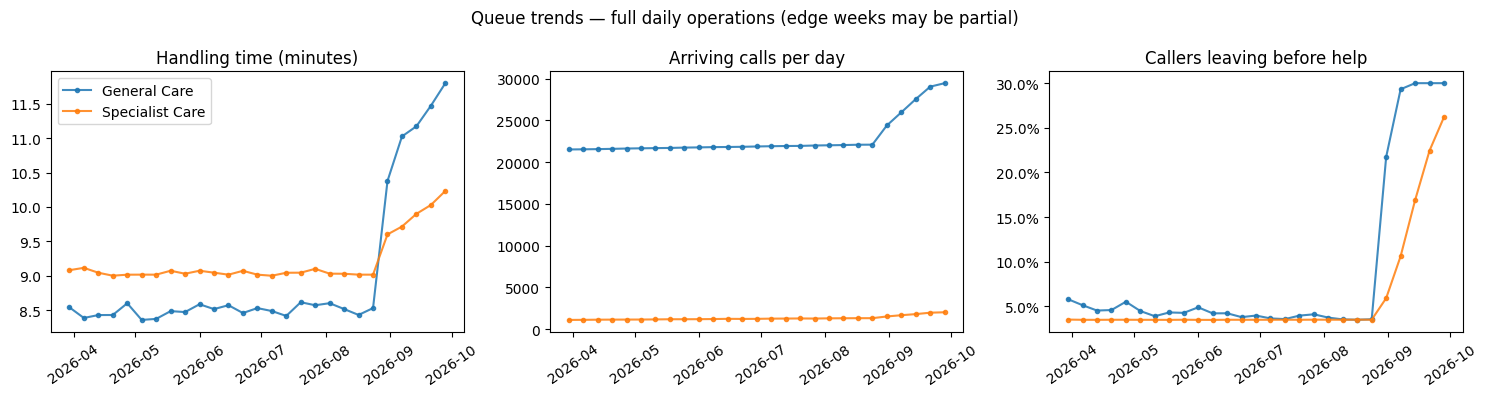

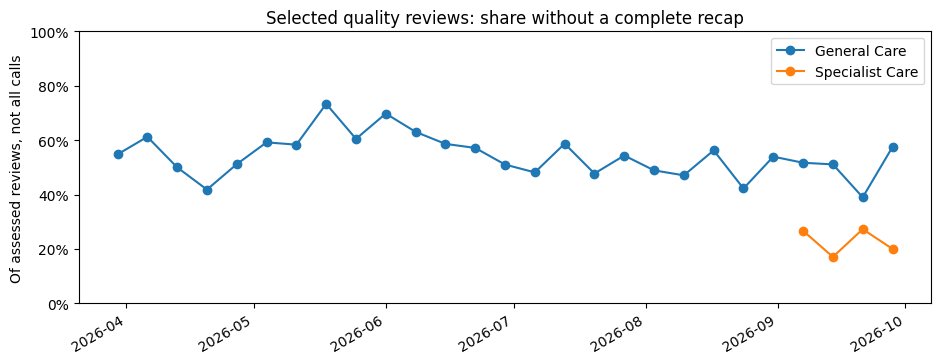

In [4]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for queue,d in report['op'].groupby('Queue'):
    for ax,col,title in zip(axes,['AHT_min','offered_per_day','abandonment'],
        ['Handling time (minutes)','Arriving calls per day','Callers leaving before help']):
        ax.plot(d.week,d[col],label=queue,marker='.',alpha=.85)
        ax.set_title(title);ax.tick_params(axis='x',rotation=35)
        if col=='abandonment':ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend();fig.suptitle('Queue trends — full daily operations (edge weeks may be partial)')
fig.tight_layout();plt.show()
qa=report['qa']
fig,ax=plt.subplots(figsize=(11,4))
for queue,d in qa[qa.Behavior.eq('Recap complete')].groupby('Queue'):
    usable=d[d.review_n.ge(settings['min_qa_per_week'])]
    ax.plot(usable.week,usable.gap_rate,marker='o',label=queue)
ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_ylim(0,1)
ax.set_title('Selected quality reviews: share without a complete recap')
ax.set_ylabel('Of assessed reviews, not all calls');ax.legend();fig.autofmt_xdate();plt.show()

## 3. Explore the interactive dashboard
Open the HTML file linked below in a browser. It works offline and needs no server. Queue, product-group and reason dropdowns update the **sampled call** chart and table. Hover over a bar for its week, average time and sample count. The backlog below the chart remains the full snapshot; filters do not change the underlying detection rules.

The embedded view may be blocked by notebook trust settings or file viewers. In that case, use the standalone HTML link or open `dashboard.html` from the printed snapshot folder. A saved GitHub notebook is a static preview; open it in Jupyter to rerun code, or use the HTML file for offline filtering.

In [5]:
# The HTML contains aggregated values only, no Guide IDs or customer comments.
try:
    relative=(out/'dashboard.html').relative_to(Path.cwd())
    display(FileLink(str(relative),result_html_prefix='Open dashboard: '))
    display(IFrame(str(relative),width='100%',height=650))
except ValueError:
    display(Markdown(f'Open this local file in a browser: `{out / "dashboard.html"}`'))

/workspace/kirby/northstar_analysis/outputs/learning/20261106T215129069639Z/dashboard.html

## 4. Why did a rule flag — or stay silent?
Every rule requires the configured number of **consecutive, complete Monday–Sunday weeks after the baseline**. A recent partial week is not compared with a full week. If the newest complete week is missing, sources are stale, or counts are too small, its status is **INSUFFICIENT / STALE**.

- **Queue signals:** handling-time and arriving-call increases use relative change against the fixed baseline. Abandonment uses percentage-point change.
- **Product/reason signals:** compare sampled average time and share of the queue’s sample. A share can rise because another issue fell; confirm the pattern with Product and Quality before calling it increased demand. The default shows individual product codes, including Unknown when missing. The optional family setting combines WN7-containing, other products, and unknown; issue type uses the recorded reason code. The HTML filters also allow combined product/reason views. The browser’s queue context and QA/feedback panels follow the queue filter; product and reason filters affect only the sampled-call chart/table.
- **QA gaps:** missing acknowledgment/recap among assessed selected reviews; recovery recognition is assessed only for eligible calls after that queue gained the approved path.
- **Repeated troubleshooting:** generic troubleshooting among eligible sampled calls after path availability. Earlier calls are not judged against an unavailable offer. The call records do not tell us how many restart steps occurred. This is not a count of repeat household contacts.
- **Feedback:** low ratings among people who responded, not all customers.

Rules are screening heuristics, not tests of causation or individual competence. Minimum counts do not remove selection bias. No alerts are sent automatically. The flag evidence spells out percentages or percentage points and includes the underlying counts. Raw weekly CSVs retain fractions for rate fields (`0.15` = 15%).

In [6]:
counts=report['evaluations'].groupby(['Queue','Status']).size().reset_index(name='Rules')
table(counts,'Rule coverage: flagged, not triggered, or not enough evidence')
table(report['evaluations'][report['evaluations'].Status.ne('Not triggered')].head(30),
 'Rules needing investigation or more evidence — first 30',
 'The full rule_evaluations.csv includes every evaluated rule. A rare product may not have enough observations to judge.')

Queue,Status,Rules
General Care,INSUFFICIENT / STALE,2039
General Care,INVESTIGATE,10
General Care,Not triggered,9
Specialist Care,INSUFFICIENT / STALE,1218
Specialist Care,INVESTIGATE,5
Specialist Care,Not triggered,6


Queue,Product,Reason,Signal,Status,Latest evaluated week ending,Evidence type
General Care,All,All,Queue handling time increase,INVESTIGATE,2026-09-27,Full daily population
General Care,All,All,Arriving calls increase,INVESTIGATE,2026-09-27,Full daily population
General Care,All,All,Callers leaving before help increase,INVESTIGATE,2026-09-27,Full daily population
General Care,All,All,Sample handling time increase,INVESTIGATE,2026-09-27,Sampled calls
General Care,All,All,Eligible calls using generic troubleshooting,INSUFFICIENT / STALE,2026-09-27,Sampled calls
General Care,All,Connectivity,Sample handling time increase,INVESTIGATE,2026-09-27,Sampled calls
General Care,All,Connectivity,Sample contact mix increase (percentage points),INVESTIGATE,2026-09-27,Sampled calls
General Care,All,Unknown,Sample handling time increase,INSUFFICIENT / STALE,2026-09-27,Sampled calls
General Care,All,Unknown,Sample contact mix increase (percentage points),INSUFFICIENT / STALE,2026-09-27,Sampled calls
General Care,CM-32,Account,Sample handling time increase,INSUFFICIENT / STALE,2026-09-27,Sampled calls


## 5. Turn a signal into a useful investigation
The weekly digest is generated automatically **each time this notebook or the command is run**. Nothing is scheduled or sent in this pilot.

1. Learning reviews the proposed priority and examples with Care Quality. Validate the behavior and whether the same issue appears across shifts.
2. Product confirms whether the pattern suggests a product problem or unclear eligibility. Operations checks search, tools, routing, staffing and transaction follow-up.
3. Choose an intervention only after that review: a product/system fix, better reference content, practice/coaching, or a combination. Assign one owner and an agreed next step.
4. Keep the investigation log up to date. A signal disappearing does not close an issue; low volume or missing data may have hidden it.

### Preserve human decisions across refreshes
`data/learning/issue_log.csv` is the persistent log. The tool creates it if needed and preserves manual fields on the next run. Stable issue IDs prevent a new copy of the same signal each week. Historical demonstration and pilot issues have separate IDs.

**Edit these columns:** `status`, `owner`, `notes`, `validated_onset_at`, `escalated_at`, `intervention_agreed_at`. Use dates/timestamps such as `2026-10-16` or `2026-10-16T15:00:00Z`; document the source of each date in notes. Blank means unknown, not zero days. Do not invent timing to fill a metric.

**Do not edit auto fields:** issue ID, mode, queue/product/reason, first detection timestamp, last-flagged timestamp, or first supported week. Detection time is when the tool actually first flagged the issue, not the report date. “First supported week” describes observed historical evidence; it is **not** validated issue onset. Keep backups and have one writer at a time.

In [7]:
display(Markdown((out/'weekly_digest.md').read_text()))
table(report['register'][['priority','signal','queue','status','owner','first_detected_at','Signal this run']].rename(
 columns={'priority':'Current priority','signal':'Investigation','queue':'Queue','status':'Human status','owner':'Owner','first_detected_at':'First tool detection (UTC)'}),
 'Persistent investigation register', 'Issues not flagged this run remain in the register. The human owner decides whether to close them.')

# Weekly learning insight digest — 2026-10-02

Mode: **historical_demo**. Historical runs are retrospective examples, not evidence of early detection.

15 sustained investigation flags; 2 complete weeks required. Baseline: 2026-08-01 to 2026-08-31.

## What to investigate first
- **P1 · General Care · Arriving calls increase** (All / All; Full daily population). Check coverage and contact mix with Workforce; ask Product and Quality for issue evidence. Evidence: Week ending 2026-09-20: +24.6% from baseline (192,758 arriving calls); Week ending 2026-09-27: +31.4% from baseline (203,199 arriving calls).
- **P1 · General Care · Callers leaving before help increase** (All / All; Full daily population). Check coverage and contact mix with Workforce; ask Product and Quality for issue evidence. Evidence: Week ending 2026-09-20: +25.8 percentage points from baseline (192,758 arriving calls); Week ending 2026-09-27: +25.8 percentage points from baseline (203,199 arriving calls).
- **P1 · General Care · Queue handling time increase** (All / All; Full daily population). Check coverage and contact mix with Workforce; ask Product and Quality for issue evidence. Evidence: Week ending 2026-09-20: +30.2% from baseline (134,931 answered calls); Week ending 2026-09-27: +33.7% from baseline (142,239 answered calls).
- **P1 · Specialist Care · Arriving calls increase** (All / All; Full daily population). Check coverage and contact mix with Workforce; ask Product and Quality for issue evidence. Evidence: Week ending 2026-09-20: +37.5% from baseline (12,582 arriving calls); Week ending 2026-09-27: +50.5% from baseline (13,776 arriving calls).
- **P1 · Specialist Care · Callers leaving before help increase** (All / All; Full daily population). Check coverage and contact mix with Workforce; ask Product and Quality for issue evidence. Evidence: Week ending 2026-09-20: +13.3 percentage points from baseline (12,582 arriving calls); Week ending 2026-09-27: +18.9 percentage points from baseline (13,776 arriving calls).
- **P2 · General Care · Sample contact mix increase (percentage points)** (All / Connectivity; Sampled calls). Inspect product and reason tags; verify pattern with Product and Quality. Sample mix is not total demand. Evidence: Week ending 2026-09-20: +24.1 percentage points from baseline (287 of 645 sampled calls); Week ending 2026-09-27: +29.0 percentage points from baseline (342 of 693 sampled calls).
- **P2 · General Care · Sample contact mix increase (percentage points)** (WN7 / All; Sampled calls). Inspect product and reason tags; verify pattern with Product and Quality. Sample mix is not total demand. Evidence: Week ending 2026-09-20: +19.9 percentage points from baseline (136 of 645 sampled calls); Week ending 2026-09-27: +25.5 percentage points from baseline (185 of 693 sampled calls).
- **P2 · General Care · Sample contact mix increase (percentage points)** (WNM-7 / All; Sampled calls). Inspect product and reason tags; verify pattern with Product and Quality. Sample mix is not total demand. Evidence: Week ending 2026-09-20: +8.5 percentage points from baseline (57 of 645 sampled calls); Week ending 2026-09-27: +12.2 percentage points from baseline (87 of 693 sampled calls).
- **P2 · General Care · Sample handling time increase** (All / All; Sampled calls). Review examples with Care Quality before choosing an intervention. Evidence: Week ending 2026-09-20: +30.0% from baseline (645 sampled calls; baseline 3216); Week ending 2026-09-27: +33.6% from baseline (693 sampled calls; baseline 3216).
- **P2 · General Care · Sample handling time increase** (All / Connectivity; Sampled calls). Review examples with Care Quality before choosing an intervention. Evidence: Week ending 2026-09-20: +66.0% from baseline (287 sampled calls; baseline 655); Week ending 2026-09-27: +64.4% from baseline (342 sampled calls; baseline 655).
- **P2 · General Care · Selected QA gap: Acknowledged practical impact** (All / All; Selected QA reviews). Calibrate reviewed examples; distinguish missing tools, unclear policy, system failures and practice needs. Evidence: Week ending 2026-09-20: 40.2% of assessed observations (92 assessed reviews); Week ending 2026-09-27: 36.4% of assessed observations (118 assessed reviews).
- **P2 · General Care · Selected QA gap: Recap complete** (All / All; Selected QA reviews). Calibrate reviewed examples; distinguish missing tools, unclear policy, system failures and practice needs. Evidence: Week ending 2026-09-20: 51.1% of assessed observations (92 assessed reviews); Week ending 2026-09-27: 39.0% of assessed observations (118 assessed reviews).

## Interpretation and next action
Sampled calls are not total demand. QA and feedback are nonrandom. Signals can reflect case mix, tagging, staffing, search or tool problems; investigate with Product and Care Quality before assigning learning.
Repeat contacts are unavailable: no stable household/account identifier or complete contact history was supplied. Guide views are off unless explicitly approved and sufficiently supported; minimum counts do not eliminate selection bias.
Inspect all 3287 rule evaluations and source coverage in the exported CSVs. Priority is a proposed investigation order, not a performance score.

## Human follow-up
Update status, owner, notes and validated timing fields in `/workspace/kirby/northstar_analysis/data/learning/issue_log.csv`. Do not overwrite existing issue IDs or auto timestamps. A disappearing flag does not close an investigation.

Current priority,Investigation,Queue,Human status,Owner,First tool detection (UTC),Signal this run
P1,Arriving calls increase,General Care,Needs investigation,Care Operations + Workforce + Learning,2026-11-06T21:48:27.020451+00:00,Flagged
P1,Callers leaving before help increase,General Care,Needs investigation,Care Operations + Workforce + Learning,2026-11-06T21:48:27.020451+00:00,Flagged
P1,Queue handling time increase,General Care,Needs investigation,Care Operations + Workforce + Learning,2026-11-06T21:48:27.020451+00:00,Flagged
P1,Arriving calls increase,Specialist Care,Needs investigation,Care Operations + Workforce + Learning,2026-11-06T21:48:27.020451+00:00,Flagged
P1,Callers leaving before help increase,Specialist Care,Needs investigation,Care Operations + Workforce + Learning,2026-11-06T21:48:27.020451+00:00,Flagged
P2,Sample contact mix increase (percentage points),General Care,Needs investigation,Learning + Care Quality,2026-11-06T21:48:27.020451+00:00,Flagged
P2,Sample contact mix increase (percentage points),General Care,Needs investigation,Learning + Care Quality,2026-11-06T21:48:27.020451+00:00,Flagged
P2,Sample contact mix increase (percentage points),General Care,Needs investigation,Learning + Care Quality,2026-11-06T21:48:27.020451+00:00,Flagged
P2,Sample handling time increase,General Care,Needs investigation,Learning + Care Quality,2026-11-06T21:48:27.020451+00:00,Flagged
P2,Sample handling time increase,General Care,Needs investigation,Learning + Care Quality,2026-11-06T21:48:27.020451+00:00,Flagged


## 6. Is the pilot helping Learning act sooner?
The measures below use only issues recorded in **pilot mode** with the required human-validated dates. Historical demonstration flags are excluded.

| Measure | Definition and limit |
|---|---|
| Time from emerging issue to detection | Median days from `validated_onset_at` to first tool detection. Unknown onset means no measurement; the first available data week is not substituted. |
| Proportion identified before escalation | Issues detected before the recorded escalation, divided by pilot issues with known detection **and escalation** dates. Issues with no escalation date are excluded, not counted as successes. Report the denominator; this subset may not represent all issues. |
| Time to agreed intervention | Median days from detection to `intervention_agreed_at`. Open/unknown interventions are excluded, so interpret beside the open backlog. |

“Not measurable yet” is an honest starting result. Negative or invalid date order must be corrected, not treated as success. No target or improvement is claimed from this packet. Review whether flags were useful and whether important issues were missed before changing thresholds.

In [8]:
table(report['success'],'Pilot success measures — no invented dates')
if not settings['guide_view_approved']:
    display(Markdown('**Guide-level view: off.** No individual rankings, automated performance labels or Guide-specific alerts are created.'))
else:
    table(report['guides'].round(1),'Approved private coaching view — sufficiently supported rows only',
      'Not a league table. Selection, case mix and unequal opportunities remain. Thresholds screen small samples; they do not establish comparable performance. Empty means nobody met the evidence requirements.')

Measure,Result,Eligible issues,Invalid date order
Days from validated onset to detection,Not measurable yet,0,0
Days from detection to agreed intervention,Not measurable yet,0,0
Detected before recorded escalation,Not measurable yet,0,0


**Guide-level view: off.** No individual rankings, automated performance labels or Guide-specific alerts are created.

## 7. Optional weekly automation — same data checks, no continuous feed
Manual use is enough for this pilot. To generate the same outputs without opening Jupyter, run from this folder:

```sh
python learning_monitor.py --config learning_settings.json
```

An administrator may schedule that command once a week **after** coordinated exports arrive. Update the settings file first, or provide an explicit date:

```sh
python learning_monitor.py --config learning_settings.json --as-of 2026-10-16
```

The command automates report production, not extraction or decisions. Nothing is scheduled by this notebook. Before scheduling, agree on the export owner, report timezone/date, service account, secure storage, failure notifications, recipient/review owner, single-writer rule for the issue log, and retention. A failed command must not publish a partly refreshed snapshot. `latest_run.json` is updated only after successful computation/export; check its completion time and source hashes rather than assuming a job ran. The CLI writes digest and dashboard files; it does not execute/save this notebook’s chart outputs.

## 8. Where to change the code as the pilot grows
| Change needed | Exact place | Recheck afterwards |
|---|---|---|
| New exports, dates, baseline, thresholds | `learning_settings.json` or **EDIT HERE** above | Source coverage, complete weeks, sample sizes, results and run manifest |
| Different workbook/sheet/column names or Yes/No values | `analysis_utils.py`, `load_data()`, its `specs` and cleaning checks | Keys, duplicates, dates, staffing joins and QA/feedback Call ID matches; update the manifest workbook list in `learning_monitor.py`, `run()` if filenames change |
| Different product grouping or reason taxonomy | `learning_monitor.py`, `prepare()` (`Product view`, `Reason view`) | Keep Unknown, validate categories, review historical comparability; do not silently remap old issue IDs |
| New flag or different sustained rule | `learning_monitor.py`, `detect()`; document its threshold in the JSON file and notebook | Zero/small counts, missing weeks, stale data, false alarms, and no automatic individual rating |
| New QA behavior | `learning_monitor.py`, `build_metrics()` (`behaviors`), and `detect()` | Yes/No applicability, eligible path availability, review selection and denominator |
| Repeat contacts become linkable | Add an authorized, complete contact-history input and a separate aggregation in `build_metrics()`; update `detect()` and dashboard labels | Stable household/account and contact IDs, full observation window, agreed repeat-contact definition, privacy controls and follow-up completeness. Do not infer repeat contacts from product, Guide ID or duplicated export rows. |
| New recovery offer or queues | `analysis_utils.py`, `load_data()` (`Recovery available`, `Complete recovery`) | Effective dates and safe branches confirmed by Care/Product; review metric definitions |
| Different digest or browser layout | `learning_monitor.py`, `run()` or `interactive_html()` | Labels, filter scope, sample limits, and no individual/customer identifiers in HTML |
| Preserve regeneration | Edit `build_learning_notebook.py` for this notebook | Running the generator recreates notebook 03 and clears its outputs; rerun notebook 03 afterwards |

**Troubleshooting:** mismatched review Call IDs require matching call exports; missing staffing days require a coordinated staffing export; no baseline means supply its history or deliberately choose another one. Newer files after the report date require a correct `as_of`, not removal of date checks. Too few observations or missing full weeks means “insufficient evidence,” not “no problem.” Notebook 01 remains the historical decision analysis; notebook 02 tracks approved recovery execution; notebook 03 broadens the investigation to emerging learning/operational needs.

In [9]:
display(Markdown(f"## Learning refresh complete\nReport **{settings['as_of']}** in **{settings['mode']}** mode. "
 f"Artifacts: `{out}`. Save this notebook to preserve its outputs. "
 'Review the digest and flags with the owners before taking action.'))

## Learning refresh complete
Report **2026-10-02** in **historical_demo** mode. Artifacts: `/workspace/kirby/northstar_analysis/outputs/learning/20261106T215129069639Z`. Save this notebook to preserve its outputs. Review the digest and flags with the owners before taking action.